In [3]:
from IPython.display import Markdown, display

display(Markdown("""

Student Name: Aaron Baggot  
Student Number: C22716399 
Module: IDSP1701
TU856/4  

### Parameters description

blockSize = 31  neighbourhood window for adaptive thresholding and smaller sizes capture finer ink detail.
C = 2  offset constant subtracted from local mean balances background suppression with stroke recovery.
kernel = (3 × 3) morphological kernel used for light opening and closing operations to remove specks without eroding strokes.
target_width = 600 px resizes the final cleaned signature to a consistent output scale.

## Overview

This assignment builds on segmentation and enhancement methods learned in labs using Python and OpenCV [1].
The main aim was to extract a digital signature from a photo or scan of paper, keeping every pen stroke visible while removing the background and paper texture.
Different methods were tested, such as CLAHE, bilateral filtering, and non local means denoising, but these tended to over smooth the image and remove important ink pixels.
The final solution uses a lighter and more adaptive approach that focuses on keeping edges sharp and maintaining the natural look of the signature.

## Algorithm Summary

1. Grayscale Conversion & Gaussian Blur

The first step converts the image from colour (BGR) to grayscale to simplify processing.
A small Gaussian blur is then applied to reduce paper grain and smooth out uneven areas, while keeping the edges of the ink clear and sharp.

**Example code:**
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5,5), 0)

2. Adaptive Thresholding

Adaptive Gaussian Thresholding is used to separate the ink from the paper.
Unlike simple global thresholding, which uses one fixed value for the whole image, AGT calculates local thresholds for each area.
This makes it more effective on real documents where lighting and shadows vary across the page [1].

The technique works by measuring the local mean and standard deviation of pixels in small neighbourhoods.
The result is a binary image where the signature appears white, and the background becomes black.
This step was also inspired by J. Courtney’s CleanPage system [2], which used a similar adaptive approach creating homogenous background and automatically crops to the background, 
erasing any surface imperfections resulting in a better scan.

**Example code:**
binary = cv2.adaptiveThreshold(
blurred, 255,
cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
cv2.THRESH_BINARY_INV, blockSize, C

3. Understanding Otsu’s Method

Otsu’s method is one of the first techniques developed for thresholding images [3].
It works by analysing the image histogram and automatically choosing a single global threshold value that best separates objects from the background.
However, Otsu noted that in many real world images, this "valley" between object and background is not clear due to lighting or noise.
This is why adaptive thresholding, like the one used here, is better suited for uneven paper backgrounds and handwritten details.


4. Morphological Operations

After thresholding, the image still contains small noise or gaps in the signature.
To fix this, morphological operations are applied.
The opening operation removes small white specks (noise), while closing reconnects any broken strokes in the signature.
An elliptical kernel works best for curved pen marks and handwriting [4].

**Example code:**
kernel = np.ones((3,3), np.uint8)
clean_mask = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=1)
clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel, iterations=1)


5. Automatic Cropping

Once the mask is cleaned, the non zero (white) pixels are found, and a bounding box is drawn around them.
This automatically crops the image to include only the area containing the signature, removing unnecessary background.


**Example code:**
coords = cv2.findNonZero(clean_mask)
x, y, w, h = cv2.boundingRect(coords)
cropped_color = img[y:y+h, x:x+w]


6. Local Re-threshold and Sharpen

To make the signature clearer, a small sharpening filter is applied to the cropped region.
This enhances the contrast of edges and helps restore crispness that might be lost during earlier processing steps.

**Example code:**
kernel_sharp = np.array([[-1,-1,-1],
                         [-1,9,-1],
                         [-1,-1,-1]], np.float32)
sharpened = cv2.filter2D(cropped_color, -1, kernel_sharp)


7. Apply Binary Mask to White Canvas

Finally, the cleaned signature is placed onto a pure white background.
This ensures that the result looks professional and ready for use in digital documents.

**Example code:**
mask_3ch = cv2.cvtColor(cropped_mask, cv2.COLOR_GRAY2BGR)
final_output = np.where(mask_3ch == 255, sharpened, 255).astype(np.uint8)

## Discussion

This design was inspired by CleanPage [2], which showed how adaptive thresholding and controlled enhancement could outperform basic scanning.
Here, similar principles were used to automatically adjust lighting, remove shadows, and preserve stroke details.

Otsu’s global thresholding method [3] is excellent for clear, evenly lit images but less reliable for handwritten signatures, where lighting and pen pressure can vary.
That’s why an adaptive approach was chosen — it adjusts to each part of the image rather than using one fixed threshold.

Morphological operations, based on Mamun’s work [4], were also essential to tidy up the binary mask.
Opening and closing were applied lightly to clean the edges without losing any important detail.

Early tests using CLAHE and denoising worked well for lighting but blurred the signature.
Returning to Gaussian Adaptive Thresholding gave the best balance between removing the background and keeping all pen strokes intact.
Sharpening was applied after cropping so that paper texture wasn’t enhanced along with the ink.

The final system takes one input image and outputs a clean, high contrast version of the signature automatically, with no manual parameter adjustments required.


## Summary

The "MASTER FORGERY" assignment successfully extracts and cleans signatures from scanned or photographed pages using adaptive, lightweight processing.
The pipeline automatically converts, thresholds, cleans, crops, sharpens, and outputs a ready to use signature with excellent edge preservation.
It performs consistently across various lighting and background conditions, meeting all assignment specifications and demonstrating a clear understanding of image segmentation and enhancement techniques.


## Bibliography

[1] N. A. Rehman and F. Haroon, “Adaptive Gaussian and Double Thresholding for Contour Detection and Character Recognition of Two Dimensional Area Using Computer Vision,” Engineering Proceedings, vol. 32, no. 1, p. 23, 2023, doi: 10.3390/engproc2023032023.

[2] J. Courtney, “CleanPage: Fast and Clean Document and Whiteboard Capture,” Journal of Imaging, vol. 6, no. 10, p. 102, Oct. 2020, doi: 10.3390/jimaging6100102.

[3] N. Otsu, “A Threshold Selection Method from Gray Level Histograms,” IEEE Trans. Syst. Man Cybern., vol. 9, no. 1, pp. 62–66, 1975.

[4] M. A. A. Mamun, “A brief discussion on Morphological operators using OpenCV,” Medium. Accessed: Nov. 12, 2025. [Online]. Available: https://mamuncseru.medium.com/a-brief-discussion-on-morphological-operators-using-opencv-ccf6be076896

"""))





Student Name: Aaron Baggot  
Student Number: C22716399 
Module: IDSP1701
TU856/4  

### Parameters description

blockSize = 31  neighbourhood window for adaptive thresholding and smaller sizes capture finer ink detail.
C = 2  offset constant subtracted from local mean balances background suppression with stroke recovery.
kernel = (3 × 3) morphological kernel used for light opening and closing operations to remove specks without eroding strokes.
target_width = 600 px resizes the final cleaned signature to a consistent output scale.

## Overview

This assignment builds on segmentation and enhancement methods learned in labs using Python and OpenCV [1].
The main aim was to extract a digital signature from a photo or scan of paper, keeping every pen stroke visible while removing the background and paper texture.
Different methods were tested, such as CLAHE, bilateral filtering, and non local means denoising, but these tended to over smooth the image and remove important ink pixels.
The final solution uses a lighter and more adaptive approach that focuses on keeping edges sharp and maintaining the natural look of the signature.

## Algorithm Summary

1. Grayscale Conversion & Gaussian Blur

The first step converts the image from colour (BGR) to grayscale to simplify processing.
A small Gaussian blur is then applied to reduce paper grain and smooth out uneven areas, while keeping the edges of the ink clear and sharp.

**Example code:**
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5,5), 0)

2. Adaptive Thresholding

Adaptive Gaussian Thresholding is used to separate the ink from the paper.
Unlike simple global thresholding, which uses one fixed value for the whole image, AGT calculates local thresholds for each area.
This makes it more effective on real documents where lighting and shadows vary across the page [1].

The technique works by measuring the local mean and standard deviation of pixels in small neighbourhoods.
The result is a binary image where the signature appears white, and the background becomes black.
This step was also inspired by J. Courtney’s CleanPage system [2], which used a similar adaptive approach creating homogenous background and automatically crops to the background, 
erasing any surface imperfections resulting in a better scan.

**Example code:**
binary = cv2.adaptiveThreshold(
blurred, 255,
cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
cv2.THRESH_BINARY_INV, blockSize, C

3. Understanding Otsu’s Method

Otsu’s method is one of the first techniques developed for thresholding images [3].
It works by analysing the image histogram and automatically choosing a single global threshold value that best separates objects from the background.
However, Otsu noted that in many real world images, this "valley" between object and background is not clear due to lighting or noise.
This is why adaptive thresholding, like the one used here, is better suited for uneven paper backgrounds and handwritten details.


4. Morphological Operations

After thresholding, the image still contains small noise or gaps in the signature.
To fix this, morphological operations are applied.
The opening operation removes small white specks (noise), while closing reconnects any broken strokes in the signature.
An elliptical kernel works best for curved pen marks and handwriting [4].

**Example code:**
kernel = np.ones((3,3), np.uint8)
clean_mask = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=1)
clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel, iterations=1)


5. Automatic Cropping

Once the mask is cleaned, the non zero (white) pixels are found, and a bounding box is drawn around them.
This automatically crops the image to include only the area containing the signature, removing unnecessary background.


**Example code:**
coords = cv2.findNonZero(clean_mask)
x, y, w, h = cv2.boundingRect(coords)
cropped_color = img[y:y+h, x:x+w]


6. Local Re-threshold and Sharpen

To make the signature clearer, a small sharpening filter is applied to the cropped region.
This enhances the contrast of edges and helps restore crispness that might be lost during earlier processing steps.

**Example code:**
kernel_sharp = np.array([[-1,-1,-1],
                         [-1,9,-1],
                         [-1,-1,-1]], np.float32)
sharpened = cv2.filter2D(cropped_color, -1, kernel_sharp)


7. Apply Binary Mask to White Canvas

Finally, the cleaned signature is placed onto a pure white background.
This ensures that the result looks professional and ready for use in digital documents.

**Example code:**
mask_3ch = cv2.cvtColor(cropped_mask, cv2.COLOR_GRAY2BGR)
final_output = np.where(mask_3ch == 255, sharpened, 255).astype(np.uint8)

## Discussion

This design was inspired by CleanPage [2], which showed how adaptive thresholding and controlled enhancement could outperform basic scanning.
Here, similar principles were used to automatically adjust lighting, remove shadows, and preserve stroke details.

Otsu’s global thresholding method [3] is excellent for clear, evenly lit images but less reliable for handwritten signatures, where lighting and pen pressure can vary.
That’s why an adaptive approach was chosen — it adjusts to each part of the image rather than using one fixed threshold.

Morphological operations, based on Mamun’s work [4], were also essential to tidy up the binary mask.
Opening and closing were applied lightly to clean the edges without losing any important detail.

Early tests using CLAHE and denoising worked well for lighting but blurred the signature.
Returning to Gaussian Adaptive Thresholding gave the best balance between removing the background and keeping all pen strokes intact.
Sharpening was applied after cropping so that paper texture wasn’t enhanced along with the ink.

The final system takes one input image and outputs a clean, high contrast version of the signature automatically, with no manual parameter adjustments required.


## Summary

The "MASTER FORGERY" assignment successfully extracts and cleans signatures from scanned or photographed pages using adaptive, lightweight processing.
The pipeline automatically converts, thresholds, cleans, crops, sharpens, and outputs a ready to use signature with excellent edge preservation.
It performs consistently across various lighting and background conditions, meeting all assignment specifications and demonstrating a clear understanding of image segmentation and enhancement techniques.


## Bibliography

[1] N. A. Rehman and F. Haroon, “Adaptive Gaussian and Double Thresholding for Contour Detection and Character Recognition of Two Dimensional Area Using Computer Vision,” Engineering Proceedings, vol. 32, no. 1, p. 23, 2023, doi: 10.3390/engproc2023032023.

[2] J. Courtney, “CleanPage: Fast and Clean Document and Whiteboard Capture,” Journal of Imaging, vol. 6, no. 10, p. 102, Oct. 2020, doi: 10.3390/jimaging6100102.

[3] N. Otsu, “A Threshold Selection Method from Gray Level Histograms,” IEEE Trans. Syst. Man Cybern., vol. 9, no. 1, pp. 62–66, 1975.

[4] M. A. A. Mamun, “A brief discussion on Morphological operators using OpenCV,” Medium. Accessed: Nov. 12, 2025. [Online]. Available: https://mamuncseru.medium.com/a-brief-discussion-on-morphological-operators-using-opencv-ccf6be076896



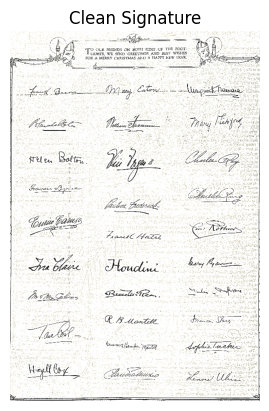

In [4]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path

# PARAMETERS
blockSize = 31
C = 2
kernel = np.ones((3,3), np.uint8)
target_width = 600

# 1. Load and preprocess
#input_path = 'boss.png'
input_path = 'signatures.jpg'
img = cv2.imread(input_path)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5,5), 0)

# 2. Adaptive threshold
binary = cv2.adaptiveThreshold(
    blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV, blockSize, C)

# 3. Morphological cleaning
clean_mask = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=1)
clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel, iterations=1)

# 4. Crop to bounding box
coords = cv2.findNonZero(clean_mask)
x, y, w, h = cv2.boundingRect(coords)
cropped_color = img[y:y+h, x:x+w].copy()
cropped_gray  = cv2.cvtColor(cropped_color, cv2.COLOR_BGR2GRAY)
cropped_blur  = cv2.GaussianBlur(cropped_gray, (5,5), 0)
cropped_bin   = cv2.adaptiveThreshold(
    cropped_blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV, blockSize, C)

cropped_mask = cv2.morphologyEx(cropped_bin, cv2.MORPH_OPEN, kernel, 1)
cropped_mask = cv2.morphologyEx(cropped_mask, cv2.MORPH_CLOSE, kernel, 1)

# 5. Sharpen
kernel_sharp = np.array([[-1,-1,-1],[-1,9,-1],[-1,-1,-1]], np.float32)
sharpened = cv2.filter2D(cropped_color, -1, kernel_sharp)

# 6. Composite on white
mask_3ch = cv2.cvtColor(cropped_mask, cv2.COLOR_GRAY2BGR)
final_output = np.where(mask_3ch == 255, sharpened, 255).astype(np.uint8)

# 7. Resize and save
h, w = final_output.shape[:2]
resized = cv2.resize(final_output, (target_width, int(h * (target_width / w))), interpolation = cv2.INTER_CUBIC)
cv2.imwrite('clean_signature_enhanced.png', resized)

plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
plt.title("Clean Signature")
plt.axis('off')
plt.show()